# Skin tone detection: how the pipeline works

This notebook walks through the `skintone` package step by step on synthetic images (no photos of people), then checks it against the 10 reference colours of the Monk Skin Tone Scale and compares it with the original version of the code.

1. **Skin mask**: keep pixels whose colour is inside skin ranges in HSV and YCrCb, then clean the mask.
2. **Dominant colour**: k-means on the skin pixels in CIELAB; the largest cluster is the skin colour.
3. **ITA**: Individual Typology Angle, `arctan((L* - 50) / b*)`, mapped to six standard categories.

In [1]:
import sys, json
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from skintone import core

MST = ["#f6ede4", "#f3e7db", "#f7ead0", "#eadaba", "#d7bd96", "#a07e56", "#825c43", "#604134", "#3a312a", "#292420"]
hex2rgb = lambda h: np.array([int(h[i:i + 2], 16) for i in (1, 3, 5)], float)

## A synthetic test image
A face-shaped patch with side lighting (a darker right side and a highlight), hair-coloured top and a blue background, plus camera noise.

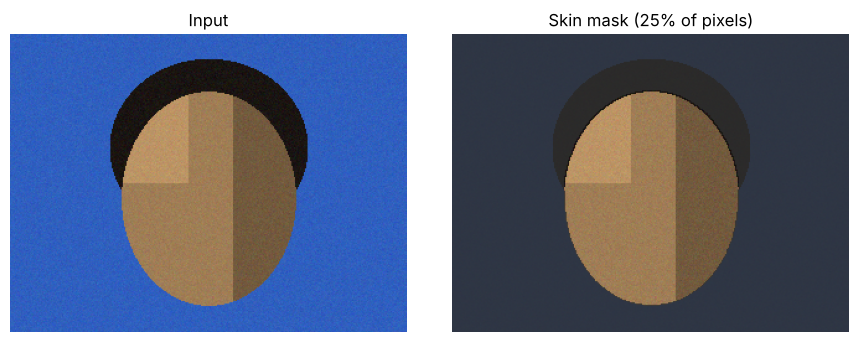

In [2]:
def scene(skin="#a07e56", bg="#3060c0", w=320, h=240, seed=0):
    rng = np.random.default_rng(seed)
    img = np.zeros((h, w, 3)); img[:] = hex2rgb(bg)
    yy, xx = np.mgrid[0:h, 0:w]
    face = ((xx - w / 2) / (w * 0.22)) ** 2 + ((yy - h * 0.55) / (h * 0.36)) ** 2 <= 1
    hair = ((xx - w / 2) / (w * 0.25)) ** 2 + ((yy - h * 0.38) / (h * 0.30)) ** 2 <= 1
    img[hair] = hex2rgb("#1a1512")
    img[face] = hex2rgb(skin)
    img[face & (xx > w * 0.56)] *= 0.72                                  # shadow
    hl = face & (xx < w * 0.45) & (yy < h * 0.5)
    img[hl] = np.minimum(255, img[hl] * 1.18)                            # highlight
    return np.clip(img + rng.normal(0, 6, img.shape), 0, 255)

img = scene()
mask = core.skin_mask(img)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
ax[0].imshow(img.astype(np.uint8)); ax[0].set_title("Input")
ax[1].imshow(np.where(mask[..., None], img, img * 0.15 + 40).astype(np.uint8)); ax[1].set_title(f"Skin mask ({mask.mean():.0%} of pixels)")
for a in ax: a.axis("off")
plt.tight_layout()

## Dominant colour with k-means
The skin pixels are clustered into 3 groups in CIELAB, where distance matches perceived colour difference. Shadow and highlight pixels form their own clusters, so they don't pull the skin colour darker or lighter.

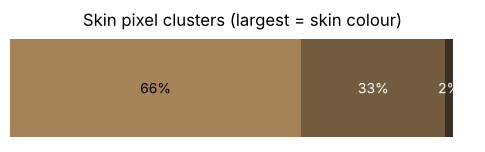

Largest cluster centre (L*, a*, b*)  ours: [56.9  8.  27.5]  scikit-learn: [55.1  7.8 26.7]


In [3]:
smooth = core.box_blur3(img)
pixels = core.sample(smooth[mask])
lab = core.rgb_to_lab(pixels)
centres, counts, labels = core.kmeans(lab)
order = np.argsort(-counts)
fig, ax = plt.subplots(figsize=(6, 1.4))
for i, j in enumerate(order):
    rgb = pixels[labels == j].mean(0) / 255
    ax.barh(0, counts[j], left=counts[order[:i]].sum(), color=rgb)
    ax.text(counts[order[:i]].sum() + counts[j] / 2, 0, f"{counts[j] / counts.sum():.0%}", ha="center", va="center",
            color="white" if rgb.mean() < .5 else "black")
ax.axis("off"); ax.set_title("Skin pixel clusters (largest = skin colour)")
plt.show()

# Cross-check: scikit-learn's KMeans finds the same largest cluster
sk = KMeans(n_clusters=3, n_init=10, random_state=0).fit(lab)
sk_top = np.bincount(sk.labels_).argmax()
print("Largest cluster centre (L*, a*, b*)  ours:", centres[order[0]].round(1), " scikit-learn:", sk.cluster_centers_[sk_top].round(1))

## Result

In [4]:
result = core.analyze_rgb(img)
print(json.dumps(result, indent=2))
true_ita = core.ita(core.rgb_to_lab(hex2rgb("#a07e56")))
print(f"ITA of the colour used to draw the face: {true_ita:.1f} degrees")

{
  "skin_pixels": 19233,
  "skin_fraction": 0.2504,
  "label": "Tan",
  "ita": 14.2,
  "lab": [
    57.0,
    8.0,
    27.5
  ],
  "rgb": [
    166,
    130,
    89
  ],
  "hex": "#a68259",
  "cluster_share": 0.657
}
ITA of the colour used to draw the face: 10.9 degrees


## All 10 Monk Skin Tone Scale colours
Each reference colour drawn into the same scene, on a different background each time.

In [5]:
bgs = ["#3060c0", "#ffffff", "#1f2a44", "#40a050", "#808080"]
rows = []
for i, c in enumerate(MST):
    r = core.analyze_rgb(scene(c, bgs[i % 5], seed=i))
    rows.append((f"MST {i + 1}", c, round(core.ita(core.rgb_to_lab(hex2rgb(c))), 1), r["ita"], r["label"]))
print(f"{'tone':7s} {'colour':8s} {'true ITA':>9s} {'measured':>9s}  label")
for row in rows:
    print(f"{row[0]:7s} {row[1]:8s} {row[2]:9.1f} {row[3]:9.1f}  {row[4]}")

tone    colour    true ITA  measured  label
MST 1   #f6ede4       83.0      83.0  Very light
MST 2   #f3e7db       80.2      80.4  Very light
MST 3   #f7ead0       71.8      71.9  Very light
MST 4   #eadaba       64.7      64.7  Very light
MST 5   #d7bd96       50.3      51.9  Light
MST 6   #a07e56       10.9      14.2  Tan
MST 7   #825c43      -20.1     -15.9  Brown
MST 8   #604134      -55.4     -52.9  Dark
MST 9   #3a312a      -78.4     -79.6  Dark
MST 10  #292420      -84.3     -84.1  Dark


## Comparison with the original code

The original version (kept unchanged in `original_ml/`) had two problems that this check shows:

- The Django version read the image as RGB but converted it as if it were BGR, so its HSV skin mask rejected every reference colour.
- Its labelling packed R, G and B into one number and compared ranges, with typos (255 and 265 instead of 256). Even with the exact colour, it put the 6 lightest tones in "fair", never returned "mild", and the 2 darkest were "Unrecognized".

In [6]:
import cv2

def original_label(rgb):
    lo = 85 * 65536 + 52 * 255 + 56; hi = 255 * 265 * 256 + 219 * 255 + 172          # as in the original code
    shades = {"dark": [[0, 0, 0], [141, 89, 85]], "mild": [[141, 89, 85], [159, 118, 85]], "fair": [[159, 118, 85], [255, 255, 255]]}
    d = rgb[0] * 65536 + rgb[1] * 256 + rgb[2]
    if not lo <= d <= hi:
        return "Unrecognized"
    for name, (a, b) in shades.items():
        if a[0] * 65536 + a[1] * 256 + a[2] <= d <= b[0] * 65536 + b[1] * 256 + b[2]:
            return name

def original_mask_share(rgb):
    patch = np.full((20, 20, 3), rgb, np.uint8)          # RGB, as matplotlib reads it
    hsv = cv2.cvtColor(patch, cv2.COLOR_BGR2HSV)         # converted as if it were BGR
    return (cv2.inRange(hsv, np.array([0, 48, 80], np.uint8), np.array([20, 255, 255], np.uint8)) > 0).mean()

print(f"{'tone':7s} {'original mask':>13s}  {'original label':15s} new label")
for i, c in enumerate(MST):
    rgb = hex2rgb(c).astype(int)
    print(f"MST {i + 1:<3d} {original_mask_share(rgb):13.0%}  {original_label(rgb):15s} {rows[i][4]}")

tone    original mask  original label  new label
MST 1              0%  fair            Very light
MST 2              0%  fair            Very light
MST 3              0%  fair            Very light
MST 4              0%  fair            Very light
MST 5              0%  fair            Light
MST 6              0%  fair            Tan
MST 7              0%  dark            Brown
MST 8              0%  dark            Dark
MST 9              0%  Unrecognized    Dark
MST 10             0%  Unrecognized    Dark


## Limitations

- Colour in a photo depends on lighting, white balance, camera processing, filters and make-up; the result describes the photo, not the person.
- Skin-coloured backgrounds (beige walls, wood) pass the colour thresholds; the API reduces this by cropping to the detected face, and the web demo lets you select an area.
- The thresholds are general-purpose ranges from the skin detection literature, checked here on synthetic reference colours, not tuned on a labelled photo dataset.
- It is not a medical or dermatological tool.